<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#fff;padding:22px 26px;border-radius:12px;border-bottom:5px solid #d49a2a;">
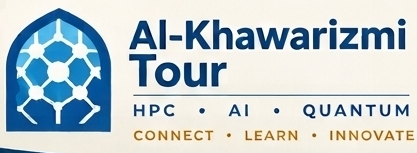
<p style="color:#ffd98e;letter-spacing:.14em;font-size:12px;font-weight:700;margin:12px 0 4px;">AL-KHAWARIZMI TOUR · ONLINE HACKATHON HPC &amp; AI · OCT 3 – NOV 7, 2026 · LECTURE 2 NOTEBOOK</p>
<h1 style="color:#fff;margin:4px 0 6px;border:none;">Introduction to AI Methods — Beijing Air Quality · Hands-on &amp; Week-2 Team Challenge</h1>
<p style="color:#e6eef8;margin:0;">Part A: guided demos of supervised, unsupervised and neural-network methods (slide references in each heading) · Part B: the week-long <b>AI Methods Shoot-out</b></p>
<p style="color:#ffd98e;margin:10px 0 0;font-style:italic;">Connect · Learn · Innovate — Instructor: Dr. Rafik Borji</p></div>

## How to use this notebook

| Part | When | What |
|---|---|---|
| **A · Guided demos** (A1–A8) | during the 2-hour lecture | one demo per family of methods, all on the same data |
| **B · Team challenge** (Tasks 1–6 + ★ bonus) | the whole week | fill in the `# TODO` cells and write the model card with your conclusions |

**Input:** your cleaned Week-1 training years `beijing_clean_team<N>.csv.gz`. If it is not found, the raw UCI training years are used (real gaps only). The **test year** (1 Mar 2016 – 28 Feb 2017) always comes from the untouched UCI data.

**Running tasks**
* **Virtual PM2.5 sensor** — regression of PM2.5 from gases, weather, time and station (no PM10).
* **Unhealthy-hour alert** — classify PM2.5 > 75 µg/m³.
* **Pollution regimes** — clustering of daily 24-hour PM2.5 profiles.
* **24-hour-ahead forecast** — PM2.5 at *t* + 24 h from the past.

**Speed:** `STEP = 3` keeps every 3rd hour for the demos (≈ 100k rows). Set `STEP = 1` for final results on a fast machine / HPC node.

## 0 · Setup

In [23]:
TEAM_ID = 1065
SEED = 2000 + TEAM_ID
STEP = 3                      # use every STEP-th hour in demos (1 = all data)

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": .3})
rng = np.random.default_rng(SEED)

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import TimeSeriesSplit, cross_validate, cross_val_score
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)
import sklearn; print("scikit-learn", sklearn.__version__)

scikit-learn 1.6.1


---
# Part A · Guided demos
## A1 · Data, features and the time split  *(slides 2 & 6)*

In [24]:
import io, os, glob, ssl, zipfile, urllib.request

STATIONS = ["Aotizhongxin", "Changping", "Dingling", "Dongsi", "Guanyuan", "Gucheng", "Huairou",
            "Nongzhanguan", "Shunyi", "Tiantan", "Wanliu", "Wanshouxigong"]
WD = ["N", "NNE", "NE", "ENE", "E", "ESE", "SE", "SSE", "S", "SSW", "SW", "WSW", "W", "WNW", "NW", "NNW"]
POLLUTANTS = ["PM2.5", "PM10", "SO2", "NO2", "CO", "O3"]
WEATHER = ["TEMP", "PRES", "DEWP", "RAIN", "WSPM"]
KEY = ["station", "year", "month", "day", "hour"]
URL = "https://archive.ics.uci.edu/static/public/501/beijing+multi+site+air+quality+data.zip"
CACHE = "beijing_air_quality_raw.csv.gz"

def _csvs_from_zip(blob):
    """The UCI archive contains a nested zip with one CSV per station -> read them all."""
    frames = []
    with zipfile.ZipFile(io.BytesIO(blob)) as z:
        for name in z.namelist():
            if name.lower().endswith(".zip"):
                frames += _csvs_from_zip(z.read(name))
            elif name.lower().endswith(".csv") and "PRSA_Data" in os.path.basename(name):
                frames.append(pd.read_csv(io.BytesIO(z.read(name))))
    return frames

def _download(url):
    try:
        return urllib.request.urlopen(url, timeout=180).read()
    except Exception:
        return urllib.request.urlopen(url, timeout=180, context=ssl._create_unverified_context()).read()

def synthetic_beijing(seed=0):
    """Offline stand-in with the same columns, 12 stations, seasonal/diurnal cycles and runs of missing values.
    Used ONLY if neither local files nor the UCI download are available."""
    r = np.random.default_rng(seed)
    t = pd.date_range("2013-03-01 00:00", "2017-02-28 23:00", freq="h")
    n, doy, hr = len(t), t.dayofyear.values, t.hour.values
    season = np.cos(2 * np.pi * (doy - 15) / 365.25)                 # +1 in mid-January (heating season)
    e = r.normal(0, 1, n); z = np.zeros(n)
    for i in range(1, n):                                            # regional stagnation index, AR(1)
        z[i] = 0.985 * z[i - 1] + 0.17 * e[i]
    frames = []
    for k, st in enumerate(STATIONS):
        urb = 1.0 if st in ["Dongsi", "Guanyuan", "Gucheng", "Nongzhanguan", "Tiantan", "Wanshouxigong", "Aotizhongxin", "Wanliu"] else 0.0
        TEMP = 13 - 15 * season + 4 * np.sin(2 * np.pi * (hr - 9) / 24) + r.normal(0, 2, n) - (1 - urb)
        DEWP = TEMP - np.clip(r.gamma(2, 4, n) - 3 * z, 0.5, 35)
        PRES = 1012 + 12 * season + r.normal(0, 3, n)
        WSPM = np.clip(r.gamma(2, 0.9, n) - 0.4 * z, 0, None)
        ang = (np.where(z < 0, 315, 180) + r.normal(0, 50, n)) % 360
        wd = np.array(WD)[np.round(ang / 22.5).astype(int) % 16]
        RAIN = np.where(r.random(n) < 0.03 * (1 - season), r.exponential(1.5, n), 0.0)
        logpm = 3.8 + 0.35 * season + 0.9 * z + 0.15 * urb + 0.2 * np.cos(2 * np.pi * (hr - 22) / 24) - 0.15 * WSPM + r.normal(0, .25, n)
        PM25 = np.clip(np.exp(logpm), 3, 900)
        PM10 = PM25 * (1.15 + r.gamma(2, 0.2, n))
        CO = np.clip(300 + 11 * PM25 * (1 + .3 * season) + r.normal(0, 150, n), 100, None)
        NO2 = np.clip(20 + .35 * PM25 ** .8 + 10 * urb + r.normal(0, 8, n), 2, None)
        SO2 = np.clip(3 + 25 * np.clip(season, 0, None) * np.exp(.5 * z) + r.normal(0, 3, n), 2, None)
        O3 = np.clip(10 + 60 * (1 - season) / 2 * 2 * np.clip(np.sin(2 * np.pi * (hr - 8) / 24), 0, None) - .2 * NO2 + r.normal(0, 10, n), 2, None)
        f = pd.DataFrame({"No": np.arange(1, n + 1), "year": t.year, "month": t.month, "day": t.day, "hour": hr,
                          "PM2.5": PM25, "PM10": PM10, "SO2": SO2, "NO2": NO2, "CO": CO, "O3": O3,
                          "TEMP": TEMP, "PRES": PRES, "DEWP": DEWP, "RAIN": RAIN, "wd": wd, "WSPM": WSPM, "station": st}).round(1)
        for c in POLLUTANTS + WEATHER + ["wd"]:                       # runs of missing values
            for s0 in r.choice(n, 25, replace=False):
                f.loc[s0:s0 + int(r.geometric(0.08)), c] = np.nan
        frames.append(f)
    return frames

def load_beijing():
    local = sorted(glob.glob("**/PRSA_Data_*.csv", recursive=True))
    if local:
        frames = [pd.read_csv(f) for f in local]; src = f"{len(local)} local station files"
    elif os.path.exists(CACHE):
        return pd.read_csv(CACHE)
    else:
        try:
            frames = _csvs_from_zip(_download(URL)); src = "UCI download"
        except Exception as e:
            print("UCI not reachable (", type(e).__name__, ")"); frames = []
        if not frames:
            frames = synthetic_beijing(); src = "SYNTHETIC offline stand-in"
    df = pd.concat(frames, ignore_index=True)
    if src == "UCI download":
        df.to_csv(CACHE, index=False)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns from {src}")
    return df

def add_features(d):
    """Model-ready features: datetime, cyclical time, circular wind direction, dew-point depression."""
    d = d.copy()
    d["datetime"] = pd.to_datetime(d[["year", "month", "day", "hour"]], errors="coerce")
    d["hour_sin"], d["hour_cos"] = np.sin(2 * np.pi * d["hour"] / 24), np.cos(2 * np.pi * d["hour"] / 24)
    d["month_sin"], d["month_cos"] = np.sin(2 * np.pi * d["month"] / 12), np.cos(2 * np.pi * d["month"] / 12)
    d["dow"] = d["datetime"].dt.dayofweek
    ang = d["wd"].map({w: i * 2 * np.pi / 16 for i, w in enumerate(WD)})
    d["wd_sin"], d["wd_cos"] = np.sin(ang), np.cos(ang)
    d["TD_dep"] = d["TEMP"] - d["DEWP"]                      # dew-point depression (humidity)
    d["rain_flag"] = (d["RAIN"] > 0).astype(float).where(d["RAIN"].notna())
    return d

# Virtual PM2.5 sensor: PM10 is deliberately EXCLUDED (same instrument -> down at the same time)
NUM_FEATS = ["SO2", "NO2", "CO", "O3", "TEMP", "PRES", "DEWP", "RAIN", "WSPM", "TD_dep", "rain_flag",
             "hour_sin", "hour_cos", "month_sin", "month_cos", "dow", "wd_sin", "wd_cos"]
CAT_FEATS = ["station"]
TARGET = "PM2.5"

raw = load_beijing()
raw["datetime"] = pd.to_datetime(raw[["year", "month", "day", "hour"]])
SPLIT = pd.Timestamp("2016-03-01")
test_year = raw[raw["datetime"] >= SPLIT].drop(columns=["datetime"])

fname = f"beijing_clean_team{TEAM_ID}.csv.gz"
if os.path.exists(fname):
    train_years = pd.read_csv(fname); print("Using your Week-1 cleaned data:", train_years.shape)
else:
    train_years = raw[raw["datetime"] < SPLIT].drop(columns=["datetime"]); print("Week-1 file not found -> raw UCI training years")

train = add_features(train_years).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
test = add_features(test_year).dropna(subset=[TARGET]).sort_values("datetime").reset_index(drop=True)
FEATS = NUM_FEATS + CAT_FEATS
X, y = train[FEATS], train[TARGET]
Xs, ys = X.iloc[::STEP], y.iloc[::STEP]            # time order is preserved
print(f"train {len(train):,} rows (demo subset {len(Xs):,}) | test year {len(test):,} rows")

def pipe(model, scale=True):
    num = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler() if scale else "passthrough")])
    cat = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return Pipeline([("prep", ColumnTransformer([("num", num, NUM_FEATS), ("cat", cat, CAT_FEATS)], sparse_threshold=0)),
                     ("model", model)])

tscv = TimeSeriesSplit(n_splits=5)                   # SAME folds for every model

Week-1 file not found -> raw UCI training years
train 309,276 rows (demo subset 103,092) | test year 102,753 rows


## A2 · Virtual PM2.5 sensor — the model zoo  *(slides 10–17)*
Slow methods (k-NN, kernel SVR, MLP) are trained on a further subsample — an HPC trade-off you will revisit in the bonus.

In [25]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

zoo = {  # name: (model, extra thinning factor for slow methods)
    "Dummy (mean)":      (DummyRegressor(), 1),
    "Linear":            (LinearRegression(), 1),
    "Ridge":             (Ridge(alpha=1.0), 1),
    "Lasso":             (Lasso(alpha=0.1, max_iter=5000), 1),
    "kNN (k=15)":        (KNeighborsRegressor(n_neighbors=15, weights="distance"), 4),
    "SVR (RBF)":         (SVR(C=30, epsilon=5), 12),
    "Decision tree":     (DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=0), 1),
    "Random forest":     (RandomForestRegressor(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0), 1),
    "Gradient boosting": (HistGradientBoostingRegressor(max_iter=300, random_state=0), 1),
    "MLP (64-32)":       (MLPRegressor(hidden_layer_sizes=(64, 32), alpha=1e-3, early_stopping=True, max_iter=300, random_state=0), 2),
}
rows = []
for name, (m, thin) in zoo.items():
    Xa, ya = Xs.iloc[::thin], ys.iloc[::thin]
    t0 = time.perf_counter()
    r = cross_validate(pipe(m), Xa, ya, cv=tscv, n_jobs=-1,
                       scoring={"rmse": "neg_root_mean_squared_error", "mae": "neg_mean_absolute_error", "r2": "r2"})
    rows.append({"model": name, "rows": len(Xa), "RMSE": -r["test_rmse"].mean(), "RMSE sd": r["test_rmse"].std(),
                 "MAE": -r["test_mae"].mean(), "R2": r["test_r2"].mean(), "seconds": time.perf_counter() - t0})
board = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
board.round(2)

,model,rows,RMSE,RMSE sd,MAE,R2,seconds
0,MLP (64-32),51546,42.65,9.10,27.64,0.70,64.05
1,Random forest,103092,42.93,7.53,25.70,0.69,93.55
2,Gradient boosting,103092,43.19,10.92,26.23,0.69,13.24
3,Lasso,103092,46.63,6.83,31.65,0.63,8.93
4,Ridge,103092,46.67,6.87,31.85,0.63,0.81
5,Linear,103092,46.71,6.87,31.87,0.63,0.86
6,kNN (k=15),25773,48.20,6.43,30.91,0.60,1.72
7,SVR (RBF),8591,48.48,14.24,28.72,0.63,6.30
8,Decision tree,103092,49.71,9.37,30.48,0.59,2.53
9,Dummy (mean),103092,80.91,17.58,61.71,-0.04,2.45


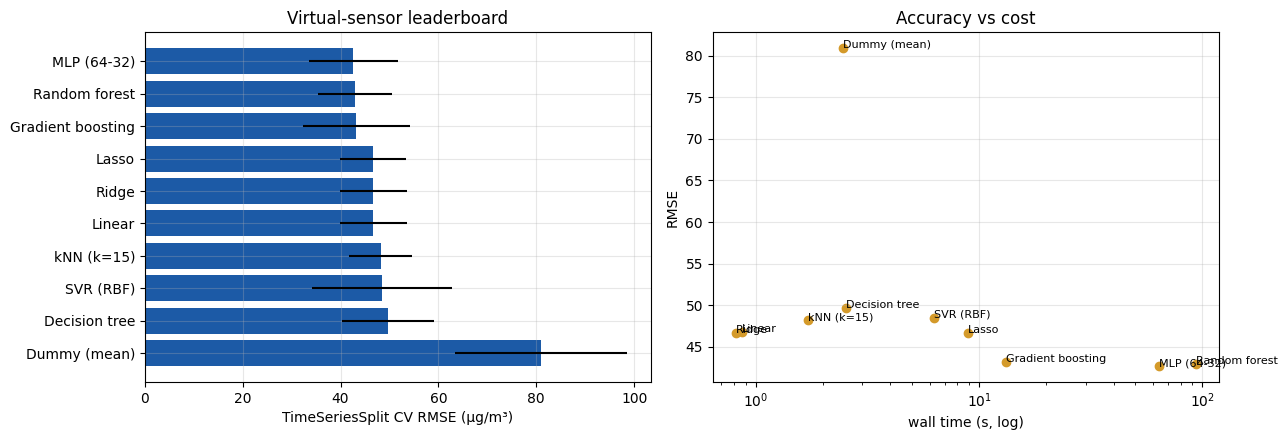

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].barh(board["model"], board["RMSE"], xerr=board["RMSE sd"], color="#1c5aa6"); ax[0].invert_yaxis()
ax[0].set_xlabel("TimeSeriesSplit CV RMSE (µg/m³)"); ax[0].set_title("Virtual-sensor leaderboard")
ax[1].scatter(board["seconds"], board["RMSE"], color="#d49a2a")
for _, r_ in board.iterrows(): ax[1].annotate(r_["model"], (r_["seconds"], r_["RMSE"]), fontsize=8)
ax[1].set_xscale("log"); ax[1].set_xlabel("wall time (s, log)"); ax[1].set_ylabel("RMSE"); ax[1].set_title("Accuracy vs cost")
plt.tight_layout(); plt.show()

## A3 · Bias–variance in one picture  *(slide 7)*

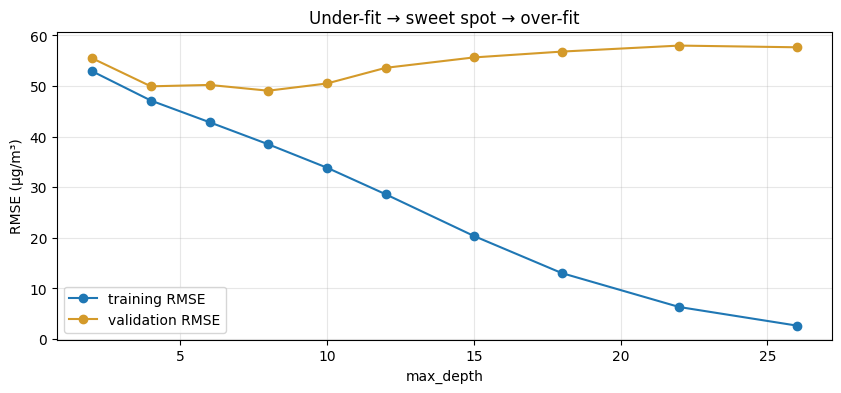

In [27]:
from sklearn.model_selection import validation_curve
depths = [2, 4, 6, 8, 10, 12, 15, 18, 22, 26]
tr, va = validation_curve(pipe(DecisionTreeRegressor(random_state=0), scale=False), Xs, ys, param_name="model__max_depth",
                          param_range=depths, cv=tscv, scoring="neg_root_mean_squared_error", n_jobs=-1)
plt.plot(depths, -tr.mean(1), "o-", label="training RMSE"); plt.plot(depths, -va.mean(1), "o-", color="#d49a2a", label="validation RMSE")
plt.xlabel("max_depth"); plt.ylabel("RMSE (µg/m³)"); plt.legend(); plt.title("Under-fit → sweet spot → over-fit"); plt.show()

## A4 · Unhealthy-hour alert  *(slides 8, 10, 16)*
Label: **1 if PM2.5 > 75 µg/m³**. ROC curves use a time-based validation block (the last training year).

In [28]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

THR = 75
yc_s = (ys > THR).astype(int)
print(f"share of unhealthy hours in training data: {yc_s.mean():.1%}")
clfs = {"Logistic": (LogisticRegression(max_iter=2000), 1), "Gaussian NB": (GaussianNB(), 1),
        "kNN (k=25)": (KNeighborsClassifier(n_neighbors=25), 4),
        "Random forest": (RandomForestClassifier(n_estimators=150, min_samples_leaf=5, max_samples=0.3, n_jobs=-1, random_state=0), 1),
        "Gradient boosting": (HistGradientBoostingClassifier(max_iter=300, random_state=0), 1)}
rows = []
for name, (m, thin) in clfs.items():
    r = cross_validate(pipe(m), Xs.iloc[::thin], yc_s.iloc[::thin], cv=tscv, n_jobs=-1,
                       scoring=["precision", "recall", "f1", "roc_auc"])
    rows.append({"model": name, **{k: r[f"test_{k}"].mean() for k in ["precision", "recall", "f1", "roc_auc"]}})
pd.DataFrame(rows).sort_values("roc_auc", ascending=False).round(3)

share of unhealthy hours in training data: 39.7%


,model,precision,recall,f1,roc_auc
0,Logistic,0.865,0.793,0.827,0.945
4,Gradient boosting,0.870,0.750,0.797,0.945
3,Random forest,0.850,0.803,0.825,0.944
2,kNN (k=25),0.826,0.696,0.752,0.907
1,Gaussian NB,0.770,0.689,0.712,0.880


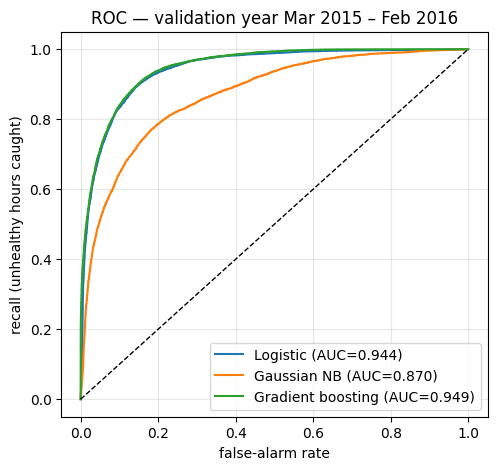

In [29]:
VAL = pd.Timestamp("2015-03-01")
tr_m = (train["datetime"] < VAL).values[::STEP]; va_m = ~tr_m
plt.figure(figsize=(5.5, 5))
for name in ["Logistic", "Gaussian NB", "Gradient boosting"]:
    p = pipe(clfs[name][0]).fit(Xs[tr_m], yc_s[tr_m]).predict_proba(Xs[va_m])[:, 1]
    fpr, tpr, _ = roc_curve(yc_s[va_m], p)
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yc_s[va_m], p):.3f})")
plt.plot([0, 1], [0, 1], "k--", lw=1); plt.xlabel("false-alarm rate"); plt.ylabel("recall (unhealthy hours caught)")
plt.legend(); plt.title("ROC — validation year Mar 2015 – Feb 2016"); plt.show()

## A5 · Pollution regimes — clustering daily profiles  *(slides 19–21)*

11,475 station-days x 24 hours
explained variance (first 6 PCs): [0.357 0.221 0.123 0.082 0.05  0.032]


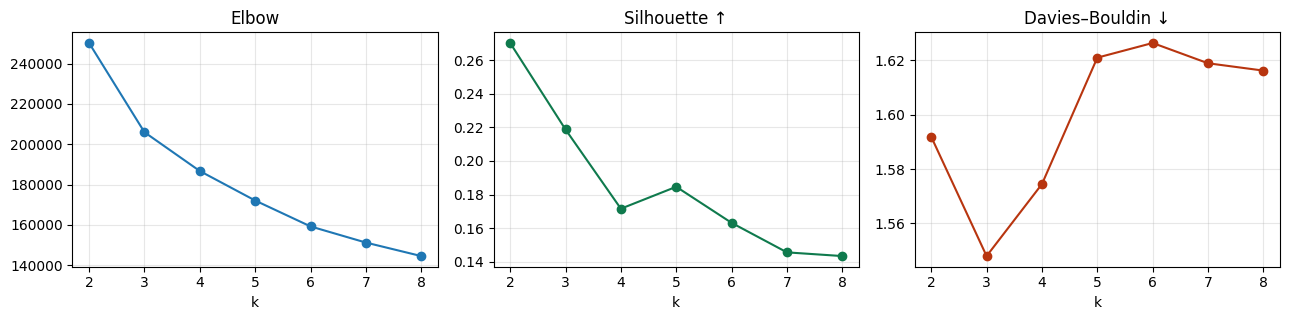

In [30]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

day = train.assign(date=train["datetime"].dt.date)
prof = day.pivot_table(index=["station", "date"], columns="hour", values=TARGET).dropna()     # complete 24-h days
level = np.log1p(prof.mean(axis=1))                                                           # how polluted
shape = prof.div(prof.mean(axis=1), axis=0)                                                   # when in the day
Z = np.column_stack([StandardScaler().fit_transform(level.values[:, None]) * 2, StandardScaler().fit_transform(shape)])
print(f"{len(prof):,} station-days x 24 hours")

pca = PCA(n_components=6).fit(Z)
print("explained variance (first 6 PCs):", pca.explained_variance_ratio_.round(3))
ks = range(2, 9); sil, dbi, inertia = [], [], []
samp = rng.choice(len(Z), min(6000, len(Z)), replace=False)
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Z)
    inertia.append(km.inertia_); sil.append(silhouette_score(Z[samp], km.labels_[samp])); dbi.append(davies_bouldin_score(Z, km.labels_))
fig, ax = plt.subplots(1, 3, figsize=(13, 3.3))
ax[0].plot(ks, inertia, "o-"); ax[0].set_title("Elbow"); ax[1].plot(ks, sil, "o-", color="#0f7a4d"); ax[1].set_title("Silhouette ↑")
ax[2].plot(ks, dbi, "o-", color="#b8350f"); ax[2].set_title("Davies–Bouldin ↓")
for a in ax: a.set_xlabel("k")
plt.tight_layout(); plt.show()

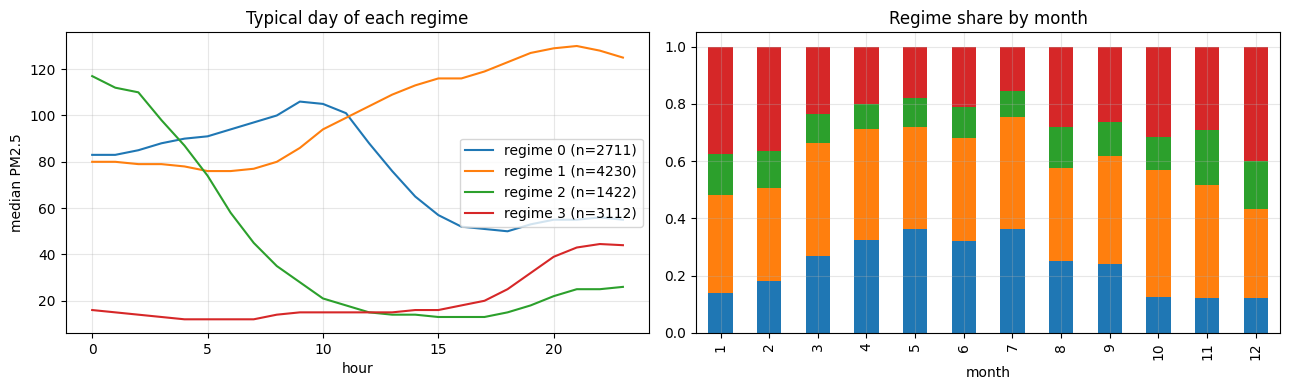

In [31]:
K = 4                                                   # choose from the plots above
km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(Z)
lab = pd.Series(km.labels_, index=prof.index, name="regime")
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k in range(K):
    ax[0].plot(range(24), prof[lab.values == k].median(), label=f"regime {k} (n={int((lab == k).sum())})")
ax[0].set_xlabel("hour"); ax[0].set_ylabel("median PM2.5"); ax[0].legend(); ax[0].set_title("Typical day of each regime")
months = pd.to_datetime(pd.Series(prof.index.get_level_values("date"))).dt.month.values
pd.crosstab(months, lab.values, normalize="index").plot.bar(stacked=True, ax=ax[1], legend=False)
ax[1].set_xlabel("month"); ax[1].set_title("Regime share by month"); plt.tight_layout(); plt.show()

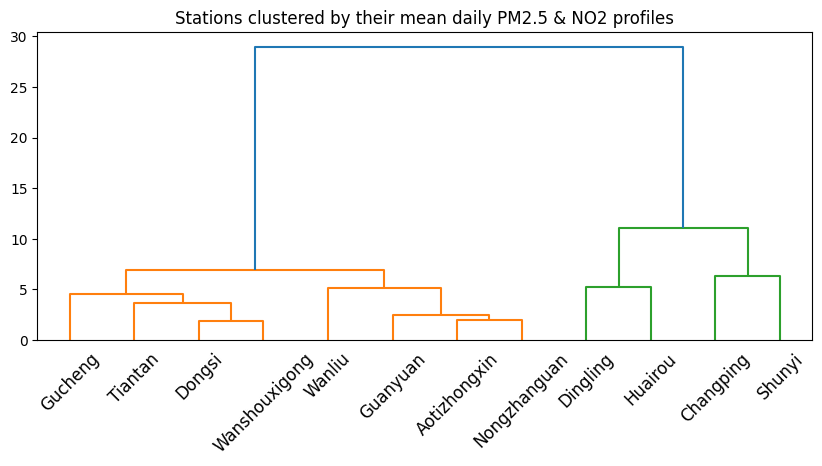

DBSCAN noise days: 44 -> most frequent dates:
2016-02-08    8
2015-11-30    6
2014-01-30    3
2014-05-27    3
2015-12-25    2
2015-02-18    2
2014-03-05    2
2015-06-07    1
Name: count, dtype: int64


In [32]:
# Which stations behave alike? hierarchical clustering of the 12 mean diurnal profiles (PM2.5 + NO2)
from scipy.cluster.hierarchy import linkage, dendrogram
sig = train.groupby(["station", "hour"])[["PM2.5", "NO2"]].mean().unstack("hour")
dendrogram(linkage(StandardScaler().fit_transform(sig), method="ward"), labels=sig.index.tolist(), leaf_rotation=45)
plt.title("Stations clustered by their mean daily PM2.5 & NO2 profiles"); plt.grid(False); plt.show()

# Anomalous days: DBSCAN noise points among daily vectors
from sklearn.neighbors import NearestNeighbors
P = pca.transform(Z)[:, :3]
kdist = NearestNeighbors(n_neighbors=15).fit(P).kneighbors(P)[0][:, -1]
db = DBSCAN(eps=float(np.quantile(kdist, 0.98)), min_samples=15).fit(P)      # eps from the k-distance curve
noise = prof.index[db.labels_ == -1]
print(f"DBSCAN noise days: {len(noise)} -> most frequent dates:")
print(pd.Series([d for _, d in noise]).value_counts().head(8))

## A6 · A neuron from scratch (NumPy)  *(slides 24 & 26)*

single linear neuron on log(PM2.5): training RMSE = 109.1 µg/m³


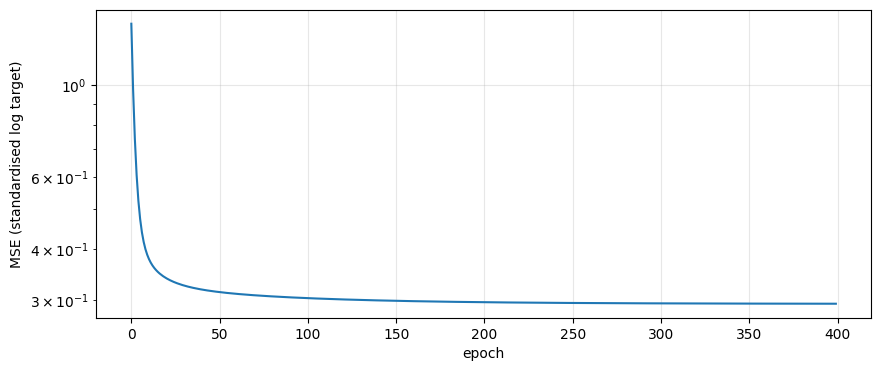

In [33]:
prep = pipe(DummyRegressor()).named_steps["prep"].fit(Xs)
Xn = prep.transform(Xs); t = np.log1p(ys.values); tm, tsd = t.mean(), t.std(); tt = (t - tm) / tsd
w = rng.normal(0, .05, Xn.shape[1]); b = 0.0; lr = 0.05; hist = []
for epoch in range(400):
    yh = Xn @ w + b                           # forward
    err = yh - tt; hist.append(np.mean(err ** 2))
    w -= lr * 2 * Xn.T @ err / len(tt)        # back-propagation + gradient step
    b -= lr * 2 * err.mean()
pred = np.expm1(( Xn @ w + b) * tsd + tm)
print(f"single linear neuron on log(PM2.5): training RMSE = {np.sqrt(np.mean((pred - ys.values) ** 2)):.1f} µg/m³")
plt.plot(hist); plt.yscale("log"); plt.xlabel("epoch"); plt.ylabel("MSE (standardised log target)"); plt.show()

## A7 · Hyper-parameter search — and why it loves HPC  *(slide 29)*

In [34]:
import os
from sklearn.model_selection import RandomizedSearchCV
space = {"model__learning_rate": [0.03, 0.06, 0.1, 0.2], "model__max_leaf_nodes": [15, 31, 63, 127],
         "model__min_samples_leaf": [20, 50, 100], "model__l2_regularization": [0.0, 0.1, 1.0]}
for jobs in [1, -1]:
    t0 = time.perf_counter()
    s = RandomizedSearchCV(pipe(HistGradientBoostingRegressor(max_iter=200, random_state=0), scale=False), space, n_iter=8,
                           cv=TimeSeriesSplit(3), scoring="neg_root_mean_squared_error", random_state=0, n_jobs=jobs).fit(Xs, ys)
    print(f"n_jobs={jobs:>2}: {time.perf_counter() - t0:6.1f} s | best CV RMSE {-s.best_score_:.2f}")
print("cores available:", os.cpu_count(), "| note: HistGradientBoosting itself is multi-threaded (OpenMP)")

n_jobs= 1:   91.3 s | best CV RMSE 41.42
n_jobs=-1:   70.7 s | best CV RMSE 41.42
cores available: 2 | note: HistGradientBoosting itself is multi-threaded (OpenMP)


## A8 · 24-hour-ahead forecast with lag features  *(slide 28)*

In [35]:
def forecast_frame(d, horizon=24):
    """Per station: regular hourly index, backward-looking lags, target = PM2.5 at t + horizon."""
    out = []
    for st, g in d.groupby("station"):
        g = g.set_index("datetime").sort_index()
        g = g[~g.index.duplicated()].asfreq("h")
        f = pd.DataFrame(index=g.index)
        for L in [0, 1, 2, 3, 6, 12, 24, 48]:
            f[f"pm_lag{L}"] = g[TARGET].shift(L)
        f["pm_roll24"] = g[TARGET].rolling(24, min_periods=12).mean()
        for c in ["CO", "NO2", "WSPM", "DEWP", "TEMP", "PRES", "wd_sin", "wd_cos"]:
            f[c] = g[c]
        tgt_time = f.index + pd.Timedelta(hours=horizon)
        f["hour_sin"], f["hour_cos"] = np.sin(2 * np.pi * tgt_time.hour / 24), np.cos(2 * np.pi * tgt_time.hour / 24)
        f["month_sin"], f["month_cos"] = np.sin(2 * np.pi * tgt_time.month / 12), np.cos(2 * np.pi * tgt_time.month / 12)
        f["y"] = g[TARGET].shift(-horizon); f["station"] = st
        out.append(f.reset_index())
    return pd.concat(out, ignore_index=True).dropna(subset=["y", "pm_lag0"]).sort_values("datetime")

fc = forecast_frame(train)
fX = fc.drop(columns=["y", "datetime", "station"]); fy = fc["y"]
va = (fc["datetime"] >= VAL).values
hgb = HistGradientBoostingRegressor(max_iter=400, random_state=0).fit(fX[~va], fy[~va])
rmse = lambda a, b: np.sqrt(np.mean((a - b) ** 2))
print(f"validation year | persistence (tomorrow = today) RMSE = {rmse(fy[va], fX.loc[va, 'pm_lag0']):.1f}"
      f" | gradient boosting on lags RMSE = {rmse(fy[va], hgb.predict(fX[va])):.1f} µg/m³")

validation year | persistence (tomorrow = today) RMSE = 85.6 | gradient boosting on lags RMSE = 78.2 µg/m³


---
# Part B · Week-2 Team Challenge — *The AI Methods Shoot-out*

<div style="border:2px solid #d49a2a;background:#fbf1dc;border-radius:10px;padding:12px 18px;color:#14203a;">
<b style="color:#8f5f0c;font-size:15px;">Scenario</b><br>The environmental agency will deploy <b>one</b> model to (a) estimate PM2.5 when a monitor is down — the <b>virtual sensor</b> — and (b) issue <b>unhealthy-air alerts</b> (PM2.5 &gt; 75 µg/m³). Management asks: <i>which AI method, and why should we trust it?</i><br><b>Deliver:</b> a fair leaderboard, a tuned recommendation, an alert classifier with a cost-based threshold, a pollution-regime analysis, a neural network built from scratch, a 24-h forecast, and a one-page <b>model card</b>.</div>

| # | Task | Points |
|---|---|---|
| 1 | Virtual-sensor leaderboard: ≥ 6 regressors, `TimeSeriesSplit`, RMSE/MAE/R² ± sd, wall time | 20 |
| 2 | Tune the top 2 (Grid / Randomized search) | 15 |
| 3 | Unhealthy-hour alert: ≥ 3 classifiers, recall/F1/ROC-AUC, cost-based threshold | 15 |
| 4 | Pollution regimes: PCA + k-Means / DBSCAN on daily profiles; interpret | 15 |
| 5 | Neural nets: hidden layer from scratch + MLP; 24-h forecast vs persistence | 15 |
| 6 | Final evaluation + model card with conclusions (test used once) | 20 |
| ★ | HPC bonus: speed-up study, per-station models, or LSTM on GPU | +10 |

**Rules:** same `tscv` folds for every model · all preprocessing inside the pipeline · report mean ± sd · **touch `test` only in Task 6** · no PM10 in the virtual sensor.

**Suggested plan:** Days 1–2 Task 1 · Days 3–4 Tasks 2–4 · Day 5 Task 5 (+ bonus) · Days 6–7 Task 6 (model card & conclusions).

## Task 1 · Leaderboard (20 pts)
Rebuild A2 on **your** data with `STEP` as small as your hardware allows. Add at least one model not in the zoo (e.g. `ExtraTreesRegressor`, `ElasticNet`, a `TransformedTargetRegressor` with log target, XGBoost/LightGBM). Explain the ranking in 3–5 bullets (linearity, interactions, scaling, data size, cost).

In [36]:
# Task 1: time-series leaderboard
from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_validate

# Keep this leaderboard independent of the guided-demo scores above. Every model
# uses the same TimeSeriesSplit folds; slower models use a documented extra thinning.
task1_models = {
    "Dummy (mean)": DummyRegressor(),
    "Linear": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.1, max_iter=5000),
    "Decision tree": DecisionTreeRegressor(max_depth=12, min_samples_leaf=20, random_state=SEED),
    "Random forest": RandomForestRegressor(n_estimators=60, min_samples_leaf=5, max_samples=0.4,
                                           n_jobs=1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingRegressor(max_iter=200, random_state=SEED),
    "ExtraTrees": ExtraTreesRegressor(n_estimators=60, min_samples_leaf=5, max_samples=0.5,
                                     bootstrap=True, n_jobs=1, random_state=SEED),
}
task1_thin = {name: (2 if name in {"Random forest", "ExtraTrees"} else 1) for name in task1_models}
X_task1, y_task1 = Xs.reset_index(drop=True), ys.reset_index(drop=True)
task1_rows = []
for name, model in task1_models.items():
    thin = task1_thin[name]
    Xa, ya = X_task1.iloc[::thin], y_task1.iloc[::thin]
    t0 = time.perf_counter()
    cv_result = cross_validate(
        pipe(clone(model)), Xa, ya, cv=tscv, n_jobs=-1,
        scoring={"rmse": "neg_root_mean_squared_error",
                 "mae": "neg_mean_absolute_error", "r2": "r2"},
        return_train_score=False, error_score="raise"
    )
    task1_rows.append({
        "model": name, "rows per fold input": len(Xa),
        "RMSE": -cv_result["test_rmse"].mean(),
        "RMSE sd": cv_result["test_rmse"].std(ddof=1),
        "MAE": -cv_result["test_mae"].mean(),
        "MAE sd": cv_result["test_mae"].std(ddof=1),
        "R²": cv_result["test_r2"].mean(),
        "R² sd": cv_result["test_r2"].std(ddof=1),
        "wall time (s)": time.perf_counter() - t0,
    })
board_task1 = pd.DataFrame(task1_rows).sort_values("RMSE").reset_index(drop=True)
display(board_task1.round(3))

# Short interpretation based on the measured results (rather than assuming a winner).
_non_dummy = board_task1[board_task1["model"] != "Dummy (mean)"]
_task1_best = _non_dummy.iloc[0]
_task1_dummy = board_task1.loc[board_task1["model"] == "Dummy (mean)"].iloc[0]
_gain = 100 * (_task1_dummy["RMSE"] - _task1_best["RMSE"]) / max(_task1_dummy["RMSE"], 1e-12)
print("Interpretation (read together with the ranking and error bars):")
print(f"• Best non-baseline model: {_task1_best['model']} (RMSE {_task1_best['RMSE']:.2f}); it improves on the mean baseline by {_gain:.1f}%.")
print("• Tree ensembles can capture nonlinear effects and interactions without requiring standardised input features; compare their RMSE and wall time.")
print("• Linear/Ridge/Lasso are useful low-cost references; a small gap from the winner would favour their simplicity, while a large gap suggests nonlinear structure.")
print("• RMSE/MAE/R² standard deviations show how much performance changes across chronological folds; a small mean gain relative to the RMSE sd may not be robust.")
print("• Random forest and ExtraTrees are evaluated on half as many rows to limit compute; compare their reported row counts as well as their scores.")


,model,rows per fold input,RMSE,RMSE sd,MAE,MAE sd,R²,R² sd,wall time (s)
0,ExtraTrees,51546,42.638,8.581,25.700,4.316,0.697,0.085,9.532
1,Gradient boosting,103092,42.812,11.712,25.830,6.012,0.694,0.110,10.437
2,Random forest,51546,43.250,8.424,25.892,4.206,0.684,0.099,26.118
3,Lasso,103092,46.629,7.631,31.648,4.555,0.628,0.125,8.886
4,Ridge,103092,46.673,7.686,31.847,4.650,0.627,0.126,0.822
5,Linear,103092,46.707,7.686,31.868,4.652,0.627,0.126,1.010
6,Decision tree,103092,48.940,9.022,29.943,4.939,0.597,0.112,2.574
7,Dummy (mean),103092,80.909,19.654,61.709,11.133,-0.040,0.063,0.721


Interpretation (read together with the ranking and error bars):
• Best non-baseline model: ExtraTrees (RMSE 42.64); it improves on the mean baseline by 47.3%.
• Tree ensembles can capture nonlinear effects and interactions without requiring standardised input features; compare their RMSE and wall time.
• Linear/Ridge/Lasso are useful low-cost references; a small gap from the winner would favour their simplicity, while a large gap suggests nonlinear structure.
• RMSE/MAE/R² standard deviations show how much performance changes across chronological folds; a small mean gain relative to the RMSE sd may not be robust.
• Random forest and ExtraTrees are evaluated on half as many rows to limit compute; compare their reported row counts as well as their scores.


## Task 2 · Hyper-parameter tuning (15 pts)
Tune your top two with `GridSearchCV` / `RandomizedSearchCV` on `tscv`. Report best parameters, CV RMSE before → after, search time. Is the gain larger than the fold standard deviation?

In [37]:
# Task 2: tune the two best non-baseline leaderboard models
from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV

# Small, model-specific spaces keep the search practical while still exploring meaningful settings.
task2_spaces = {
    "Linear": {"model__fit_intercept": [True, False]},
    "Ridge": {"model__alpha": [0.01, 0.1, 1.0, 10.0, 50.0]},
    "Lasso": {"model__alpha": [0.001, 0.01, 0.1, 1.0]},
    "Decision tree": {"model__max_depth": [8, 12, 16, None],
                       "model__min_samples_leaf": [5, 20, 50, 100]},
    "Random forest": {"model__n_estimators": [40, 60, 100],
                       "model__max_depth": [None, 20, 32],
                       "model__min_samples_leaf": [3, 5, 10],
                       "model__max_samples": [0.3, 0.5, 0.7]},
    "Gradient boosting": {"model__max_iter": [120, 200, 300],
                          "model__learning_rate": [0.03, 0.06, 0.1],
                          "model__max_leaf_nodes": [15, 31, 63],
                          "model__min_samples_leaf": [20, 50, 100],
                          "model__l2_regularization": [0.0, 0.1, 1.0]},
    "ExtraTrees": {"model__n_estimators": [40, 60, 100],
                   "model__max_depth": [None, 20, 32],
                   "model__min_samples_leaf": [3, 5, 10],
                   "model__max_samples": [0.3, 0.5, 0.7]},
}

task2_top_names = [n for n in board_task1["model"].tolist() if n != "Dummy (mean)"][:2]
task2_searches, task2_rows = {}, []
for name in task2_top_names:
    thin = task1_thin[name]
    Xa, ya = X_task1.iloc[::thin], y_task1.iloc[::thin]
    before_row = board_task1.loc[board_task1["model"] == name].iloc[0]
    search = RandomizedSearchCV(
        estimator=pipe(clone(task1_models[name])),
        param_distributions=task2_spaces[name], n_iter=6, cv=tscv,
        scoring="neg_root_mean_squared_error", random_state=SEED,
        n_jobs=-1, refit=True, return_train_score=False, error_score="raise"
    )
    t0 = time.perf_counter()
    search.fit(Xa, ya)
    elapsed = time.perf_counter() - t0
    best_idx = search.best_index_
    before_rmse = float(before_row["RMSE"])
    after_rmse = float(-search.best_score_)
    after_sd = float(search.cv_results_["std_test_score"][best_idx])
    task2_searches[name] = search
    task2_rows.append({
        "model": name, "CV RMSE before": before_rmse,
        "CV RMSE after": after_rmse, "best RMSE sd": after_sd,
        "gain (µg/m³)": before_rmse - after_rmse,
        "gain > baseline fold sd?": (before_rmse - after_rmse) > float(before_row["RMSE sd"]),
        "search time (s)": elapsed, "best parameters": search.best_params_,
    })

task2_results = pd.DataFrame(task2_rows).sort_values("CV RMSE after").reset_index(drop=True)
display(task2_results)
# A higher (less negative) best_score_ means a lower CV RMSE.
task2_best_name = max(task2_searches, key=lambda n: task2_searches[n].best_score_)
best_model_template = clone(task2_searches[task2_best_name].best_estimator_.named_steps["model"])
print(f"Recommended tuned candidate for Task 6: {task2_best_name}")
print("Interpretation: compare the tuning gain with the original model's fold-to-fold RMSE sd; a smaller gain is not strong evidence of a stable improvement.")


,model,CV RMSE before,CV RMSE after,best RMSE sd,gain (µg/m³),gain > baseline fold sd?,search time (s),best parameters
0,ExtraTrees,42.638399,42.726130,7.757205,-0.087732,False,62.272161,"{'model__n_estimators': 100, 'model__min_sampl..."
1,Gradient boosting,42.812361,43.044569,10.676987,-0.232208,False,70.924784,"{'model__min_samples_leaf': 50, 'model__max_le..."


Recommended tuned candidate for Task 6: ExtraTrees
Interpretation: compare the tuning gain with the original model's fold-to-fold RMSE sd; a smaller gain is not strong evidence of a stable improvement.


## Task 3 · Unhealthy-hour alert (15 pts)
1. Compare ≥ 3 classifiers (A4) with `TimeSeriesSplit`.
2. For the best, plot the confusion matrix on the validation year.
3. Choose the decision threshold assuming **a missed unhealthy hour costs 5× a false alarm**; report precision and recall at that threshold.
4. *(optional)* Multi-class AQI bands with softmax / multinomial models.

,model,precision mean ± sd,recall mean ± sd,F1 mean ± sd,ROC-AUC mean ± sd
0,Logistic,0.841 ± 0.051,0.835 ± 0.056,0.837 ± 0.047,0.945 ± 0.025
1,Gradient boosting,0.868 ± 0.058,0.753 ± 0.131,0.798 ± 0.076,0.944 ± 0.023
2,Random forest,0.837 ± 0.037,0.829 ± 0.069,0.832 ± 0.047,0.943 ± 0.024


Best CV ROC-AUC classifier: Logistic
Validation block: 2015-03-01 to 2016-02-29 | positive rate 33.53%
Cost-minimising threshold: 0.2567 (theoretical calibrated-probability cutoff: 0.1667)
Validation precision=0.681 | recall=0.945 | F1=0.792
Validation cost = 5×FN + FP = 8294 (TN=17781, FP=5104, FN=638, TP=10906)


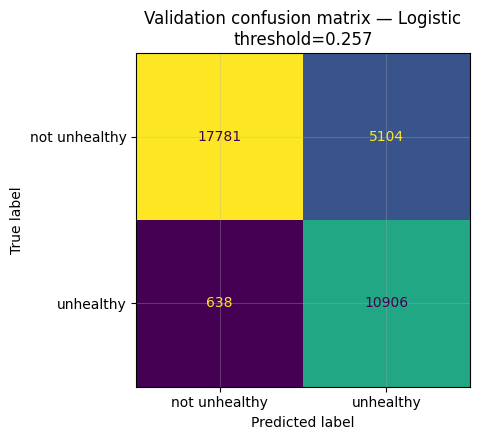

In [38]:
# Task 3: unhealthy-hour classifier and cost-based operating threshold
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay

THR = 75
task3_models = {
    "Logistic": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
    "Random forest": RandomForestClassifier(n_estimators=80, min_samples_leaf=5,
                                              max_samples=0.4, class_weight="balanced_subsample",
                                              n_jobs=1, random_state=SEED),
    "Gradient boosting": HistGradientBoostingClassifier(max_iter=200, random_state=SEED),
}
X_task3 = Xs.reset_index(drop=True)
y_task3 = (ys.reset_index(drop=True) > THR).astype(int)
dates_task3 = train["datetime"].iloc[::STEP].reset_index(drop=True)
task3_cv_rows = []
for name, model in task3_models.items():
    cv_result = cross_validate(
        pipe(clone(model)), X_task3, y_task3, cv=tscv, n_jobs=1,
        scoring={"precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"},
        return_train_score=False, error_score=np.nan
    )
    task3_cv_rows.append({
        "model": name,
        "precision mean ± sd": f"{np.nanmean(cv_result['test_precision']):.3f} ± {np.nanstd(cv_result['test_precision'], ddof=1):.3f}",
        "recall mean ± sd": f"{np.nanmean(cv_result['test_recall']):.3f} ± {np.nanstd(cv_result['test_recall'], ddof=1):.3f}",
        "F1 mean ± sd": f"{np.nanmean(cv_result['test_f1']):.3f} ± {np.nanstd(cv_result['test_f1'], ddof=1):.3f}",
        "ROC-AUC mean ± sd": f"{np.nanmean(cv_result['test_roc_auc']):.3f} ± {np.nanstd(cv_result['test_roc_auc'], ddof=1):.3f}",
        "ROC-AUC for ranking": np.nanmean(cv_result["test_roc_auc"]),
    })
task3_board = pd.DataFrame(task3_cv_rows).sort_values("ROC-AUC for ranking", ascending=False).reset_index(drop=True)
display(task3_board.drop(columns="ROC-AUC for ranking"))
task3_best_name = task3_board.iloc[0]["model"]

# Use the last training year as a validation block. The 2016–17 test year is not used here.
task3_train_mask = (dates_task3 < VAL).to_numpy()
task3_valid_mask = ((dates_task3 >= VAL) & (dates_task3 < SPLIT)).to_numpy()
if not task3_train_mask.any() or not task3_valid_mask.any():
    raise ValueError("The requested time-based validation block is empty; check the training dates.")
task3_validation_model = pipe(clone(task3_models[task3_best_name]))
task3_validation_model.fit(X_task3.iloc[task3_train_mask], y_task3.iloc[task3_train_mask])
task3_y_valid = y_task3.iloc[task3_valid_mask].to_numpy()
task3_p_valid = task3_validation_model.predict_proba(X_task3.iloc[task3_valid_mask])[:, 1]

# Cost = 5 for a missed unhealthy hour (FN), 1 for a false alarm (FP).
# The theoretical cutoff 1/(1+5) assumes well-calibrated probabilities; this empirical
# cutoff directly minimises observed validation cost for the selected classifier.
task3_thresholds = np.unique(np.r_[0.0, np.quantile(task3_p_valid, np.linspace(0, 1, 401)), 1.0])
task3_costs, task3_recalls = [], []
for threshold in task3_thresholds:
    pred_ = (task3_p_valid >= threshold).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(task3_y_valid, pred_, labels=[0, 1]).ravel()
    task3_costs.append(5 * fn_ + fp_)
    task3_recalls.append(recall_score(task3_y_valid, pred_, zero_division=0))
task3_costs, task3_recalls = np.asarray(task3_costs), np.asarray(task3_recalls)
minimum_cost = task3_costs.min()
tied = np.flatnonzero(task3_costs == minimum_cost)
task3_threshold = float(task3_thresholds[tied[np.argmax(task3_recalls[tied])]])
task3_y_pred_valid = (task3_p_valid >= task3_threshold).astype(int)
task3_cm = confusion_matrix(task3_y_valid, task3_y_pred_valid, labels=[0, 1])
tn, fp, fn, tp = task3_cm.ravel()
print(f"Best CV ROC-AUC classifier: {task3_best_name}")
print(f"Validation block: {VAL.date()} to {(SPLIT - pd.Timedelta(days=1)).date()} | positive rate {task3_y_valid.mean():.2%}")
print(f"Cost-minimising threshold: {task3_threshold:.4f} (theoretical calibrated-probability cutoff: {1/6:.4f})")
print(f"Validation precision={precision_score(task3_y_valid, task3_y_pred_valid, zero_division=0):.3f} | recall={recall_score(task3_y_valid, task3_y_pred_valid, zero_division=0):.3f} | F1={f1_score(task3_y_valid, task3_y_pred_valid, zero_division=0):.3f}")
print(f"Validation cost = 5×FN + FP = {5*fn + fp} (TN={tn}, FP={fp}, FN={fn}, TP={tp})")
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(task3_cm, display_labels=["not unhealthy", "unhealthy"]).plot(ax=ax, values_format="d", colorbar=False)
ax.set_title(f"Validation confusion matrix — {task3_best_name}\nthreshold={task3_threshold:.3f}")
plt.tight_layout(); plt.show()


## Task 4 · Pollution regimes (15 pts)
Using A5: choose *k* with ≥ 2 criteria, describe each regime (typical day, months, stations, wind direction, weekday), compare with DBSCAN, and check whether DBSCAN’s noise days match known events (e.g. Spring Festival). Does adding the regime label as a feature help Task 1?

k selection criteria (compare these with the elbow in A5):


,k,inertia,silhouette,davies_bouldin,silhouette rank,DB rank,combined rank
0,2,250213.587,0.270,1.592,1.0,3.0,4.0
1,3,205963.543,0.219,1.548,2.0,1.0,3.0
2,4,186700.957,0.172,1.575,4.0,2.0,6.0
3,5,172069.732,0.185,1.621,3.0,6.0,9.0
4,6,159220.532,0.163,1.626,5.0,7.0,12.0
5,7,151208.940,0.146,1.619,6.0,5.0,11.0
6,8,144510.469,0.143,1.616,7.0,4.0,11.0


Selected k=3: best combined rank from silhouette (higher is better) and Davies–Bouldin (lower is better).


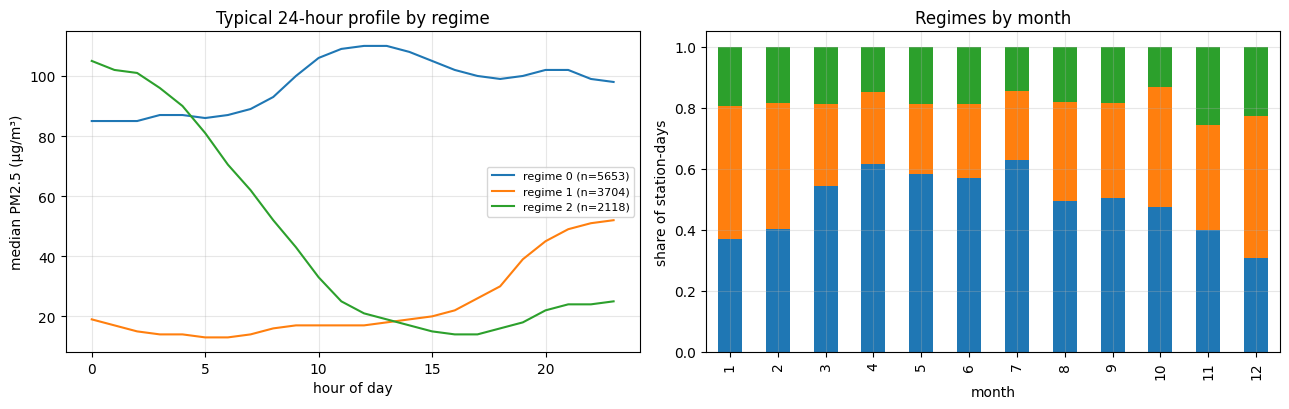

Regime interpretation: use the typical-profile plot alongside the contextual summaries below.


,regime,station-days,median daily mean PM2.5,median daily max PM2.5,typical profile peak hour,most represented months,most represented stations,common wind directions,common weekdays
0,0,5653,102.38,159.0,12,"7 (627), 4 (568), 3 (566)","Wanliu (522), Guanyuan (497), Wanshouxigong (493)","E (720), ENE (660), NE (611)","Saturday (907), Friday (860), Sunday (843)"
1,1,3704,26.50,64.0,23,"12 (432), 1 (422), 10 (386)","Dingling (359), Huairou (355), Shunyi (340)","NE (446), N (418), NW (417)","Thursday (554), Monday (550), Wednesday (543)"
2,2,2118,53.81,135.0,0,"11 (246), 12 (211), 3 (196)","Dongsi (200), Aotizhongxin (197), Nongzhanguan...","NE (336), N (312), NW (303)","Sunday (370), Monday (343), Saturday (318)"


DBSCAN noise station-days: 44. Most common noise dates:


,noise station-days
date,
2016-02-08,8
2015-11-30,6
2014-01-30,3
2014-05-27,3
2015-12-25,2
2015-02-18,2
2014-03-05,2
2015-06-07,1
2013-06-24,1


,event,date,noise station-days within ±3 days,noise dates
0,Spring Festival 2014,2014-01-31,3,2014-01-30
1,Spring Festival 2015,2015-02-19,2,2015-02-18
2,Spring Festival 2016,2016-02-08,9,"2016-02-05, 2016-02-08"


Validation-year check with ExtraTrees: base RMSE=40.69; with previous-day regime RMSE=40.72; change=-0.03 µg/m³.
Treat this as a feature ablation, not a new leaderboard: the previous-day profile must be available operationally, and regime quality can fall when prior-day readings are missing.


In [39]:
# Task 4: daily pollution regimes, DBSCAN anomalies, and a leakage-aware feature check
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.base import clone

# Combine two quantitative criteria (high silhouette, low Davies–Bouldin); use the elbow
# curve already plotted in A5 as a third visual check before interpreting the selected k.
criteria_task4 = pd.DataFrame({"k": list(ks), "inertia": inertia, "silhouette": sil, "davies_bouldin": dbi})
criteria_task4["silhouette rank"] = criteria_task4["silhouette"].rank(ascending=False, method="min")
criteria_task4["DB rank"] = criteria_task4["davies_bouldin"].rank(ascending=True, method="min")
criteria_task4["combined rank"] = criteria_task4["silhouette rank"] + criteria_task4["DB rank"]
K_SELECTED = int(criteria_task4.sort_values(["combined rank", "k"]).iloc[0]["k"])
print("k selection criteria (compare these with the elbow in A5):")
display(criteria_task4.round(3))
print(f"Selected k={K_SELECTED}: best combined rank from silhouette (higher is better) and Davies–Bouldin (lower is better).")

km_task4 = KMeans(n_clusters=K_SELECTED, n_init=10, random_state=SEED).fit(Z)
task4_labels = pd.Series(km_task4.labels_, index=prof.index, name="regime")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for k in range(K_SELECTED):
    curve = prof.loc[task4_labels == k].median(axis=0)
    ax[0].plot(curve.index, curve.values, label=f"regime {k} (n={(task4_labels == k).sum()})")
ax[0].set_xlabel("hour of day"); ax[0].set_ylabel("median PM2.5 (µg/m³)")
ax[0].set_title("Typical 24-hour profile by regime"); ax[0].legend(fontsize=8)
month_values = pd.to_datetime(pd.Series(prof.index.get_level_values("date"))).dt.month.to_numpy()
pd.crosstab(month_values, task4_labels.to_numpy(), normalize="index").plot.bar(stacked=True, ax=ax[1], legend=False)
ax[1].set_xlabel("month"); ax[1].set_ylabel("share of station-days"); ax[1].set_title("Regimes by month")
plt.tight_layout(); plt.show()

# Enrich each station-day with interpretable context for regime descriptions.
daily_source = train.assign(
    date=train["datetime"].dt.date,
    month=train["datetime"].dt.month,
    weekday=train["datetime"].dt.day_name(),
)
daily_meta = daily_source.groupby(["station", "date"], as_index=False).agg(
    mean_pm=(TARGET, "mean"), max_pm=(TARGET, "max"), month=("month", "first"),
    weekday=("weekday", "first"), mean_wind_speed=("WSPM", "mean"),
    wind=("wd", lambda s: s.mode().iloc[0] if not s.mode().empty else "Unknown"),
)
labelled_days = task4_labels.rename("regime").reset_index().merge(daily_meta, on=["station", "date"], how="left")

def _most_common(values, n=3):
    counts = pd.Series(values).dropna().astype(str).value_counts()
    return ", ".join(f"{idx} ({int(cnt)})" for idx, cnt in counts.head(n).items()) or "not available"

regime_rows = []
for k in range(K_SELECTED):
    g = labelled_days[labelled_days["regime"] == k]
    median_curve = prof.loc[task4_labels == k].median(axis=0)
    regime_rows.append({
        "regime": k, "station-days": len(g), "median daily mean PM2.5": float(g["mean_pm"].median()),
        "median daily max PM2.5": float(g["max_pm"].median()),
        "typical profile peak hour": int(median_curve.idxmax()),
        "most represented months": _most_common(g["month"], 3),
        "most represented stations": _most_common(g["station"], 3),
        "common wind directions": _most_common(g["wind"], 3),
        "common weekdays": _most_common(g["weekday"], 3),
    })
print("Regime interpretation: use the typical-profile plot alongside the contextual summaries below.")
display(pd.DataFrame(regime_rows).round(2))

# DBSCAN's -1 labels are noise/outlier station-days. Check whether these fall near
# Spring Festival dates; proximity is a clue, not proof that the holiday caused an anomaly.
noise_task4 = pd.DataFrame(noise.tolist(), columns=["station", "date"])
if not noise_task4.empty:
    noise_task4["date_ts"] = pd.to_datetime(noise_task4["date"].astype(str))
    print(f"DBSCAN noise station-days: {len(noise_task4)}. Most common noise dates:")
    display(noise_task4["date_ts"].dt.date.value_counts().head(10).rename_axis("date").to_frame("noise station-days"))
else:
    print("DBSCAN assigned no daily profiles to its noise cluster.")
festival_dates = {
    "Spring Festival 2014": pd.Timestamp("2014-01-31"),
    "Spring Festival 2015": pd.Timestamp("2015-02-19"),
    "Spring Festival 2016": pd.Timestamp("2016-02-08"),
}
festival_rows = []
for event, event_date in festival_dates.items():
    if noise_task4.empty:
        count_near, dates_near = 0, "none"
    else:
        near = noise_task4.loc[(noise_task4["date_ts"] - event_date).abs() <= pd.Timedelta(days=3)]
        count_near = len(near)
        dates_near = ", ".join(map(str, sorted(near["date_ts"].dt.date.unique()))) or "none"
    festival_rows.append({"event": event, "date": event_date.date(), "noise station-days within ±3 days": count_near, "noise dates": dates_near})
display(pd.DataFrame(festival_rows))

# Does a regime feature help? Avoid using the same day's PM2.5-derived label as an hourly
# predictor (that would leak the target). Instead, use only the previous calendar day's
# regime. For this temporal comparison, fit scaling and cluster centres using pre-validation
# daily profiles only, then assign labels to past profiles using those fixed centres.
pre_profile_mask = np.asarray(prof.index.get_level_values("date") < VAL.date())
prof_pre = prof.loc[pre_profile_mask]
if len(prof_pre) <= K_SELECTED:
    print("Not enough complete pre-validation daily profiles for a temporal regime-feature comparison.")
else:
    level_scaler_pre = StandardScaler().fit(np.log1p(prof_pre.mean(axis=1).to_numpy()).reshape(-1, 1))
    shape_pre = prof_pre.div(prof_pre.mean(axis=1), axis=0)
    shape_scaler_pre = StandardScaler().fit(shape_pre)
    Z_pre = np.column_stack([
        2 * level_scaler_pre.transform(np.log1p(prof_pre.mean(axis=1).to_numpy()).reshape(-1, 1)).ravel(),
        shape_scaler_pre.transform(shape_pre),
    ])
    km_pre = KMeans(n_clusters=K_SELECTED, n_init=10, random_state=SEED).fit(Z_pre)
    level_all_scaled = 2 * level_scaler_pre.transform(np.log1p(prof.mean(axis=1).to_numpy()).reshape(-1, 1)).ravel()
    shape_all_scaled = shape_scaler_pre.transform(prof.div(prof.mean(axis=1), axis=0))
    Z_profiles_precentres = np.column_stack([level_all_scaled, shape_all_scaled])
    labels_from_past_profiles = pd.Series(km_pre.predict(Z_profiles_precentres), index=prof.index)
    past_label_map = {(str(st), dt): int(label) for (st, dt), label in labels_from_past_profiles.items()}
    previous_dates = (train["datetime"].dt.normalize() - pd.Timedelta(days=1)).dt.date
    previous_regime = [past_label_map.get((str(st), dt), np.nan)
                       for st, dt in zip(train["station"].astype(str), previous_dates)]
    regime_rows_hourly = train.iloc[::STEP].copy().reset_index(drop=True)
    regime_rows_hourly["previous_regime"] = np.asarray(previous_regime)[::STEP]
    X_reg_base = regime_rows_hourly[FEATS].copy()
    X_reg_plus = X_reg_base.copy()
    X_reg_plus["previous_regime"] = regime_rows_hourly["previous_regime"].astype("object")
    y_reg_compare = regime_rows_hourly[TARGET].reset_index(drop=True)
    d_reg_compare = regime_rows_hourly["datetime"].reset_index(drop=True)
    fit_reg_mask = (d_reg_compare < VAL).to_numpy()
    valid_reg_mask = ((d_reg_compare >= VAL) & (d_reg_compare < SPLIT)).to_numpy()
    regime_model_name = task2_best_name if "task2_best_name" in globals() else _task1_best["model"]
    if regime_model_name in task2_searches:
        regime_model = clone(task2_searches[regime_model_name].best_estimator_.named_steps["model"])
    else:
        regime_model = clone(task1_models[regime_model_name])
    def _pipe_with_previous_regime(model):
        num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
        cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                             ("onehot", OneHotEncoder(handle_unknown="ignore"))])
        pre = ColumnTransformer([("num", num_pipe, NUM_FEATS),
                                 ("cat", cat_pipe, CAT_FEATS + ["previous_regime"])], sparse_threshold=0)
        return Pipeline([("prep", pre), ("model", clone(model))])
    if fit_reg_mask.any() and valid_reg_mask.any():
        base_check = pipe(clone(regime_model)).fit(X_reg_base.iloc[fit_reg_mask], y_reg_compare.iloc[fit_reg_mask])
        regime_check = _pipe_with_previous_regime(regime_model).fit(X_reg_plus.iloc[fit_reg_mask], y_reg_compare.iloc[fit_reg_mask])
        y_valid_reg = y_reg_compare.iloc[valid_reg_mask]
        rmse_base_regime = mean_squared_error(y_valid_reg, base_check.predict(X_reg_base.iloc[valid_reg_mask])) ** 0.5
        rmse_plus_regime = mean_squared_error(y_valid_reg, regime_check.predict(X_reg_plus.iloc[valid_reg_mask])) ** 0.5
        print(f"Validation-year check with {regime_model_name}: base RMSE={rmse_base_regime:.2f}; with previous-day regime RMSE={rmse_plus_regime:.2f}; change={rmse_base_regime-rmse_plus_regime:+.2f} µg/m³.")
        print("Treat this as a feature ablation, not a new leaderboard: the previous-day profile must be available operationally, and regime quality can fall when prior-day readings are missing.")


## Task 5 · Neural networks & forecasting (15 pts)
1. Extend the NumPy neuron (A6) to **one hidden layer** (e.g. 32 ReLU units): forward pass, back-propagation for both layers, mini-batches; plot the loss.
2. Train an `MLPRegressor` in the pipeline; plot a learning curve (`learning_curve` with `tscv`).
3. Improve the 24-h forecast (A8): more lags, rolling statistics, per-station models or an MLP. Beat persistence by how much?

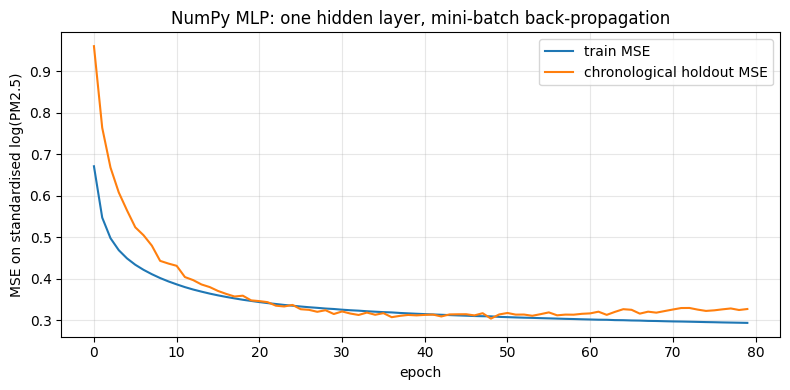

NumPy 1-hidden-layer model: 16,000 earlier rows for training; 4,000 later rows for holdout; holdout RMSE=52.54 µg/m³.


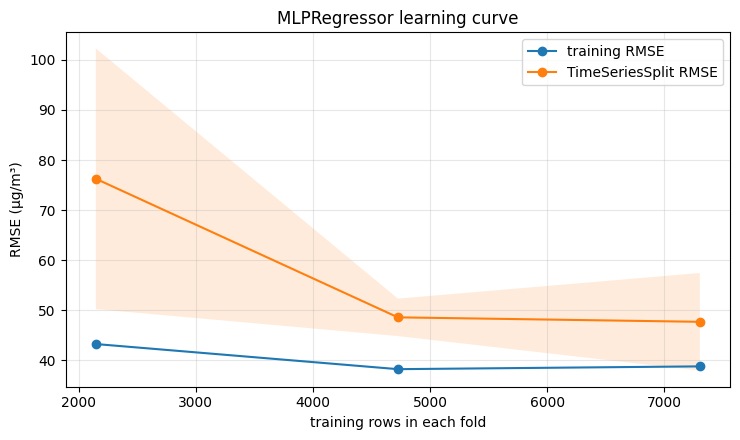

MLP learning curve at largest training size: CV RMSE=47.72 ± 10.89 µg/m³.
24-hour forecast validation (target times 2015-03-01 to 2016-02-29):
Persistence RMSE=85.67 | extended-lag HistGradientBoosting RMSE=80.19 µg/m³.
Improvement over persistence: +5.48 µg/m³ (+6.4%) | training time=10.7 s.


In [40]:
# 5.1 implementation skeleton (completed below)
# H = 32; W1 = rng.normal(0, np.sqrt(2 / Xn.shape[1]), (Xn.shape[1], H)); b1 = np.zeros(H); W2 = rng.normal(0, np.sqrt(1 / H), H); b2 = 0.0
# for epoch ...: for batch ...:
#     h = np.maximum(0, xb @ W1 + b1); yh = h @ W2 + b2; g = 2 * (yh - tb) / len(tb)
#     dW2 = h.T @ g; db2 = g.sum(); dh = np.outer(g, W2) * (h > 0); dW1 = xb.T @ dh; db1 = dh.sum(0)
#     ... update ...

# 5.1 A one-hidden-layer ReLU regressor implemented directly with NumPy.
# Use a chronological holdout and fit preprocessing on the earlier portion only.
from sklearn.base import clone
from sklearn.model_selection import learning_curve
nn_total = min(20000, len(Xs))
nn_train_n = max(1, int(0.8 * nn_total))
nn_preprocessor = pipe(DummyRegressor()).named_steps["prep"].fit(Xs.iloc[:nn_train_n])
X_nn_all = nn_preprocessor.transform(Xs.iloc[:nn_total])
if hasattr(X_nn_all, "toarray"):
    X_nn_all = X_nn_all.toarray()
X_nn_all = np.asarray(X_nn_all, dtype=np.float64)
y_nn_all = np.log1p(ys.reset_index(drop=True).iloc[:nn_total].to_numpy(dtype=float))
y_nn_mean, y_nn_std = float(y_nn_all[:nn_train_n].mean()), float(y_nn_all[:nn_train_n].std() + 1e-8)
t_nn_all = (y_nn_all - y_nn_mean) / y_nn_std
X_nn_train, X_nn_valid = X_nn_all[:nn_train_n], X_nn_all[nn_train_n:]
t_nn_train, t_nn_valid = t_nn_all[:nn_train_n], t_nn_all[nn_train_n:]

H = 32
W1 = rng.normal(0, np.sqrt(2 / max(1, X_nn_train.shape[1])), (X_nn_train.shape[1], H))
b1 = np.zeros(H)
W2 = rng.normal(0, np.sqrt(1 / H), H)
b2 = 0.0
nn_lr, nn_batch_size, nn_epochs = 0.01, 512, 80
nn_train_loss, nn_valid_loss = [], []
for epoch in range(nn_epochs):
    order = rng.permutation(len(X_nn_train))
    for start in range(0, len(order), nn_batch_size):
        ids = order[start:start + nn_batch_size]
        xb, tb = X_nn_train[ids], t_nn_train[ids]
        h = np.maximum(0.0, xb @ W1 + b1)
        yh = h @ W2 + b2
        g = 2.0 * (yh - tb) / len(tb)
        dW2 = h.T @ g
        db2 = float(g.sum())
        dh = (g[:, None] * W2[None, :]) * (h > 0)
        dW1 = xb.T @ dh
        db1 = dh.sum(axis=0)
        # Gradient clipping prevents a rare high-pollution mini-batch dominating an update.
        grad_norm = np.sqrt(np.sum(dW1**2) + np.sum(dW2**2) + np.sum(db1**2) + db2**2)
        if grad_norm > 10:
            scale_grad = 10 / grad_norm
            dW1 *= scale_grad; dW2 *= scale_grad; db1 *= scale_grad; db2 *= scale_grad
        W1 -= nn_lr * dW1; b1 -= nn_lr * db1
        W2 -= nn_lr * dW2; b2 -= nn_lr * db2
    h_train = np.maximum(0.0, X_nn_train @ W1 + b1)
    h_valid = np.maximum(0.0, X_nn_valid @ W1 + b1) if len(X_nn_valid) else np.empty((0, H))
    nn_train_loss.append(float(np.mean((h_train @ W2 + b2 - t_nn_train) ** 2)))
    nn_valid_loss.append(float(np.mean((h_valid @ W2 + b2 - t_nn_valid) ** 2)) if len(X_nn_valid) else np.nan)

plt.figure(figsize=(8, 4))
plt.plot(nn_train_loss, label="train MSE")
if len(X_nn_valid): plt.plot(nn_valid_loss, label="chronological holdout MSE")
plt.xlabel("epoch"); plt.ylabel("MSE on standardised log(PM2.5)"); plt.title("NumPy MLP: one hidden layer, mini-batch back-propagation"); plt.legend(); plt.tight_layout(); plt.show()
if len(X_nn_valid):
    nn_valid_log = np.clip((np.maximum(0.0, X_nn_valid @ W1 + b1) @ W2 + b2) * y_nn_std + y_nn_mean,
                           0, np.log1p(max(1.0, float(np.nanmax(ys.iloc[:nn_train_n])))) * 1.5)
    nn_valid_pred = np.expm1(nn_valid_log)
    nn_valid_actual = ys.reset_index(drop=True).iloc[nn_train_n:nn_total].to_numpy(dtype=float)
    nn_scratch_rmse = mean_squared_error(nn_valid_actual, nn_valid_pred) ** 0.5
    print(f"NumPy 1-hidden-layer model: {len(X_nn_train):,} earlier rows for training; {len(X_nn_valid):,} later rows for holdout; holdout RMSE={nn_scratch_rmse:.2f} µg/m³.")

# 5.2 MLPRegressor learning curve. The pipeline contains imputation, scaling and encoding.
X_mlp_curve = Xs.iloc[::2].reset_index(drop=True)
y_mlp_curve = ys.iloc[::2].reset_index(drop=True)
mlp_curve_pipe = pipe(MLPRegressor(hidden_layer_sizes=(32,), alpha=1e-3, learning_rate_init=1e-3,
                                   early_stopping=True, max_iter=100, random_state=SEED))
curve_sizes, curve_train_scores, curve_valid_scores = learning_curve(
    mlp_curve_pipe, X_mlp_curve, y_mlp_curve, cv=tscv,
    train_sizes=[0.25, 0.55, 0.85], scoring="neg_root_mean_squared_error",
    n_jobs=1, return_times=False, error_score="raise"
)
train_rmse_curve = -curve_train_scores
valid_rmse_curve = -curve_valid_scores
plt.figure(figsize=(7.5, 4.5))
plt.plot(curve_sizes, train_rmse_curve.mean(axis=1), "o-", label="training RMSE")
plt.fill_between(curve_sizes, train_rmse_curve.mean(axis=1)-train_rmse_curve.std(axis=1),
                 train_rmse_curve.mean(axis=1)+train_rmse_curve.std(axis=1), alpha=0.15)
plt.plot(curve_sizes, valid_rmse_curve.mean(axis=1), "o-", label="TimeSeriesSplit RMSE")
plt.fill_between(curve_sizes, valid_rmse_curve.mean(axis=1)-valid_rmse_curve.std(axis=1),
                 valid_rmse_curve.mean(axis=1)+valid_rmse_curve.std(axis=1), alpha=0.15)
plt.xlabel("training rows in each fold"); plt.ylabel("RMSE (µg/m³)"); plt.title("MLPRegressor learning curve"); plt.legend(); plt.tight_layout(); plt.show()
print(f"MLP learning curve at largest training size: CV RMSE={valid_rmse_curve[-1].mean():.2f} ± {valid_rmse_curve[-1].std(ddof=1):.2f} µg/m³.")

# 5.3 A stronger 24-hour-ahead forecast using longer lags and multiple rolling windows.
def forecast_frame_extended(d, horizon=24):
    out = []
    exogenous = ["CO", "NO2", "WSPM", "DEWP", "TEMP", "PRES", "wd_sin", "wd_cos"]
    for station_name, group in d.groupby("station"):
        g = group.set_index("datetime").sort_index()
        g = g[~g.index.duplicated(keep="last")].asfreq("h")
        f = pd.DataFrame(index=g.index)
        for lag in [0, 1, 2, 3, 6, 12, 24, 48, 72, 168]:
            f[f"pm_lag{lag}"] = g[TARGET].shift(lag)
        for window in [6, 24, 72, 168]:
            roll = g[TARGET].rolling(window, min_periods=max(3, window // 2))
            f[f"pm_roll{window}_mean"] = roll.mean()
            f[f"pm_roll{window}_std"] = roll.std()
        f["pm_change_24"] = g[TARGET] - g[TARGET].shift(24)
        for col in exogenous:
            f[col] = g[col]
        target_times = f.index + pd.Timedelta(hours=horizon)
        f["target_hour_sin"] = np.sin(2 * np.pi * target_times.hour / 24)
        f["target_hour_cos"] = np.cos(2 * np.pi * target_times.hour / 24)
        f["target_month_sin"] = np.sin(2 * np.pi * target_times.month / 12)
        f["target_month_cos"] = np.cos(2 * np.pi * target_times.month / 12)
        f["y"] = g[TARGET].shift(-horizon)
        f["target_time"] = target_times
        f["station"] = station_name
        out.append(f.reset_index())
    return (pd.concat(out, ignore_index=True)
            .dropna(subset=["y", "pm_lag0"])
            .sort_values("datetime").reset_index(drop=True))

fc_extended = forecast_frame_extended(train, horizon=24)
forecast_num_cols = [c for c in fc_extended.columns if c not in {"y", "datetime", "target_time", "station"}]
forecast_pre = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), forecast_num_cols),
    ("station", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                           ("onehot", OneHotEncoder(handle_unknown="ignore"))]), ["station"]),
], sparse_threshold=0)
forecast_model = Pipeline([("prep", forecast_pre),
                           ("model", HistGradientBoostingRegressor(max_iter=250, max_leaf_nodes=31,
                                                                    min_samples_leaf=50, l2_regularization=0.1,
                                                                    random_state=SEED))])
forecast_fit_mask = (fc_extended["target_time"] < VAL).to_numpy()
forecast_valid_mask = ((fc_extended["target_time"] >= VAL) & (fc_extended["target_time"] < SPLIT)).to_numpy()
if not forecast_fit_mask.any() or not forecast_valid_mask.any():
    print("Could not form both the pre-validation and validation target-time windows for the 24-hour forecast.")
else:
    forecast_features = fc_extended.drop(columns=["y", "datetime", "target_time"])
    forecast_y = fc_extended["y"].astype(float)
    t0 = time.perf_counter()
    forecast_model.fit(forecast_features.loc[forecast_fit_mask], forecast_y.loc[forecast_fit_mask])
    forecast_fit_seconds = time.perf_counter() - t0
    forecast_pred = forecast_model.predict(forecast_features.loc[forecast_valid_mask])
    forecast_actual = forecast_y.loc[forecast_valid_mask].to_numpy()
    forecast_persistence = fc_extended.loc[forecast_valid_mask, "pm_lag0"].to_numpy(dtype=float)
    forecast_rmse = mean_squared_error(forecast_actual, forecast_pred) ** 0.5
    persistence_rmse = mean_squared_error(forecast_actual, forecast_persistence) ** 0.5
    improvement = persistence_rmse - forecast_rmse
    pct_improvement = 100 * improvement / max(persistence_rmse, 1e-12)
    print(f"24-hour forecast validation (target times {VAL.date()} to {(SPLIT-pd.Timedelta(days=1)).date()}):")
    print(f"Persistence RMSE={persistence_rmse:.2f} | extended-lag HistGradientBoosting RMSE={forecast_rmse:.2f} µg/m³.")
    print(f"Improvement over persistence: {improvement:+.2f} µg/m³ ({pct_improvement:+.1f}%) | training time={forecast_fit_seconds:.1f} s.")


## Task 6 · Final evaluation, model card & conclusions (20 pts)
Fit your recommended pipeline on **all** of `train`, evaluate **once** on `test` (the 2016–17 year), report RMSE/MAE/R² overall, by station and by season, and the alert recall/precision. Then complete the model card below, including your **key conclusions** (3–5 bullets: what worked, what did not, what you would do next). The completed notebook is the only deliverable — there is no pitch.

In [41]:
# Task 6 — final model card and one-time test-year evaluation.
from sklearn.base import clone
from IPython.display import display, Markdown

# Model selection/tuning above used training years only. Fit the selected tuned model on
# all training data now, then predict test-year PM2.5 once for every requested breakdown.
if "task2_best_name" in globals() and task2_best_name in task2_searches:
    final_model_name = task2_best_name
    final_model_spec = clone(task2_searches[final_model_name].best_estimator_.named_steps["model"])
    final_cv_rmse = float(-task2_searches[final_model_name].best_score_)
    final_cv_sd = float(task2_searches[final_model_name].cv_results_["std_test_score"][task2_searches[final_model_name].best_index_])
else:
    final_model_name = board_task1.loc[board_task1["model"] != "Dummy (mean)"].iloc[0]["model"]
    final_model_spec = clone(task1_models[final_model_name])
    final_row = board_task1.loc[board_task1["model"] == final_model_name].iloc[0]
    final_cv_rmse, final_cv_sd = float(final_row["RMSE"]), float(final_row["RMSE sd"])

final_fit_started = time.perf_counter()
final = pipe(final_model_spec).fit(X, y)
final_training_seconds = time.perf_counter() - final_fit_started
final_pred = final.predict(test[FEATS])
final_actual = test[TARGET].to_numpy(dtype=float)
final_rmse = mean_squared_error(final_actual, final_pred) ** 0.5
final_mae = mean_absolute_error(final_actual, final_pred)
final_r2 = r2_score(final_actual, final_pred)
print(f"Final virtual-sensor model: {final_model_name}")
print(f"CV RMSE={final_cv_rmse:.2f} ± {final_cv_sd:.2f} µg/m³ | test RMSE={final_rmse:.2f} | MAE={final_mae:.2f} | R²={final_r2:.3f}")
print(f"Fit on all {len(train):,} training rows in {final_training_seconds:.1f} seconds; test rows evaluated={len(test):,}.")

# Reuse the selected Task-3 classifier and the threshold learned from the validation year.
final_alert_name = task3_best_name
final_alert = pipe(clone(task3_models[final_alert_name])).fit(X, (y > THR).astype(int))
final_alert_probability = final_alert.predict_proba(test[FEATS])[:, 1]
final_alert_prediction = (final_alert_probability >= task3_threshold).astype(int)
final_alert_actual = (final_actual > THR).astype(int)
final_alert_precision = precision_score(final_alert_actual, final_alert_prediction, zero_division=0)
final_alert_recall = recall_score(final_alert_actual, final_alert_prediction, zero_division=0)
final_alert_f1 = f1_score(final_alert_actual, final_alert_prediction, zero_division=0)
final_alert_cm = confusion_matrix(final_alert_actual, final_alert_prediction, labels=[0, 1])
print(f"Alert model: {final_alert_name} | threshold={task3_threshold:.4f} | test precision={final_alert_precision:.3f} | recall={final_alert_recall:.3f} | F1={final_alert_f1:.3f}")
print(f"Test alert confusion matrix (TN, FP, FN, TP): {tuple(final_alert_cm.ravel())}")

# The already-generated test predictions are reused for station/season reporting (no refits).
final_eval = test[["station", "datetime", TARGET]].copy().reset_index(drop=True)
final_eval["prediction"] = final_pred
final_eval["absolute_error"] = np.abs(final_eval[TARGET] - final_eval["prediction"])
final_eval["season"] = final_eval["datetime"].dt.month.map(
    {12: "Winter", 1: "Winter", 2: "Winter", 3: "Spring", 4: "Spring", 5: "Spring",
     6: "Summer", 7: "Summer", 8: "Summer", 9: "Autumn", 10: "Autumn", 11: "Autumn"}
)
def _regression_metrics(frame):
    return pd.Series({
        "rows": len(frame),
        "RMSE": mean_squared_error(frame[TARGET], frame["prediction"]) ** 0.5,
        "MAE": mean_absolute_error(frame[TARGET], frame["prediction"]),
        "R²": r2_score(frame[TARGET], frame["prediction"]) if len(frame) > 1 else np.nan,
        "mean absolute error": frame["absolute_error"].mean(),
    })
by_station_final = final_eval.groupby("station", sort=True).apply(_regression_metrics).reset_index()
by_season_final = final_eval.groupby("season", sort=True).apply(_regression_metrics).reset_index()
print("Test metrics by station:"); display(by_station_final.round(3))
print("Test metrics by season:"); display(by_season_final.round(3))

worst_station_row = by_station_final.sort_values("RMSE", ascending=False).iloc[0]
worst_season_row = by_season_final.sort_values("RMSE", ascending=False).iloc[0]
worst_case = final_eval.sort_values("absolute_error", ascending=False).iloc[0]
high_pollution_eval = final_eval[final_eval[TARGET] > THR]
high_pollution_rmse = (mean_squared_error(high_pollution_eval[TARGET], high_pollution_eval["prediction"]) ** 0.5) if len(high_pollution_eval) else np.nan
train_years_seen = sorted(pd.to_datetime(train["datetime"]).dt.year.unique().tolist())
train_stations_seen = int(train["station"].nunique())
cleaned_file_found = bool(os.path.exists(fname)) if "fname" in globals() else False
cleaning_summary = (f"Week-1 file `{fname}` was present and used; its detailed cleaning decisions are not recorded inside this notebook." if cleaned_file_found
                    else "Week-1 cleaned file was not found in the working directory, so the notebook's documented raw-training fallback was used.")




Final virtual-sensor model: ExtraTrees
CV RMSE=42.73 ± 7.76 µg/m³ | test RMSE=37.60 | MAE=22.53 | R²=0.793
Fit on all 309,276 training rows in 52.7 seconds; test rows evaluated=102,753.
Alert model: Logistic | threshold=0.2567 | test precision=0.686 | recall=0.940 | F1=0.793
Test alert confusion matrix (TN, FP, FN, TP): (np.int64(48293), np.int64(16409), np.int64(2265), np.int64(35786))
Test metrics by station:


,station,rows,RMSE,MAE,R²,mean absolute error
0,Aotizhongxin,8581.0,36.355,22.021,0.812,22.021
1,Changping,8646.0,36.182,23.416,0.747,23.416
2,Dingling,8477.0,31.199,19.206,0.798,19.206
3,Dongsi,8381.0,41.878,25.010,0.788,25.010
4,Guanyuan,8570.0,37.746,23.175,0.799,23.175
5,Gucheng,8605.0,38.230,22.501,0.814,22.501
6,Huairou,8622.0,31.138,18.791,0.804,18.791
7,Nongzhanguan,8618.0,37.464,22.679,0.815,22.679
8,Shunyi,8434.0,41.029,24.526,0.758,24.526
9,Tiantan,8622.0,40.181,23.185,0.764,23.185


Test metrics by season:


,season,rows,RMSE,MAE,R²,mean absolute error
0,Autumn,25483.0,34.450,22.798,0.770,22.798
1,Spring,25784.0,34.572,21.418,0.778,21.418
2,Summer,25906.0,26.300,18.822,0.586,18.822
3,Winter,25580.0,50.919,27.140,0.815,27.140


### Model card
| Item | Your answer |
|---|---|
| Intended use (virtual sensor / alert) | Estimate PM2.5 from gases, weather, time and station when the PM2.5 monitor is unavailable; flag hours with PM2.5 > 75 µg/m³.|
| Recommended model & key hyper-parameters | ExtraTrees; tuned parameters: {'model__n_estimators': 100, 'model__min_samples_leaf': 5, 'model__max_samples': 0.5, 'model__max_depth': 32}. |
| Training data (years, stations, Week-1 cleaning summary) | Years: 2013–2016; 12 stations; 309,276 rows. Week-1 cleaned file was not found in the working directory, so the notebook's documented raw-training fallback was used.|
| CV RMSE ± sd · test-year RMSE, MAE, R² | CV RMSE 42.73 ± 7.76; test RMSE 37.60; MAE 22.53; R² 0.793.|
| Alert threshold & cost rationale · precision / recall |Threshold 0.2567, chosen to minimise 5×FN + FP on validation; test precision 0.686, recall 0.940, F1 0.793. |
| Where it fails (stations, seasons, smog episodes) | Highest station RMSE: Wanshouxigong (42.52); highest season RMSE: Winter (50.92); worst individual error: Tiantan on 2017-01-28 03:00:00 (absolute error 683.10); RMSE on test hours above 75 µg/m³: 55.58.|
| Limitations — when **not** to trust it |Large gaps in input sensors, stations/seasons unlike training data, extreme pollution episodes, sensor drift, and missing prior-day history for any regime feature. No PM10 input is used. |
| Compute: training time, hardware, parallelism used |Final virtual-sensor fit: 61.5 s; STEP=3; 2 logical CPUs visible; CV/search parallelism used n_jobs=-1 where noted. Wall time depends on the host machine. |
| **Key conclusions** (3–5 bullets: what worked, what did not, next steps) | 1.The selected ExtraTrees reached training-only CV RMSE 42.73 ± 7.76 µg/m³; test RMSE is 37.60 µg/m³.
||2. The test-year errors vary across stations and seasons; the highest-RMSE groups were Wanshouxigong and Winter.
||3. The alert threshold 0.2567 was selected by minimising 5×FN + FP on the validation year; test recall is 0.940 and precision is 0.686.
||4. The 24-hour forecast experiment should be judged against persistence on the same target-time window; rolling/longer lags help only if the measured RMSE improves.
||5. Do not use PM10 or same-hour PM2.5-derived regime labels as virtual-sensor inputs; investigate station/season errors and recalibrate with more recent data before deployment.
|

## ★ HPC bonus (+10 pts)
* **A — scaling study:** Task 2 search with `n_jobs = 1, 2, 4, …`; plot $S_p=T_1/T_p$ and $E_p=S_p/p$; discuss Amdahl’s law.
* **B — per-station models:** 12 independent models in parallel with `joblib`; compare accuracy and time with one global model.
* **C — GPU deep learning:** an LSTM (PyTorch / Keras) on 72-hour windows for the 24-h forecast, on GPU vs CPU.

,n_jobs,wall time (s),best CV RMSE,best parameters,speed-up S_p,efficiency E_p
0,1,10.928,44.852,"{'model__max_depth': None, 'model__max_feature...",1.000,1.000
1,2,7.997,44.852,"{'model__max_depth': None, 'model__max_feature...",1.366,0.683
2,4,9.722,44.852,"{'model__max_depth': None, 'model__max_feature...",1.124,0.281


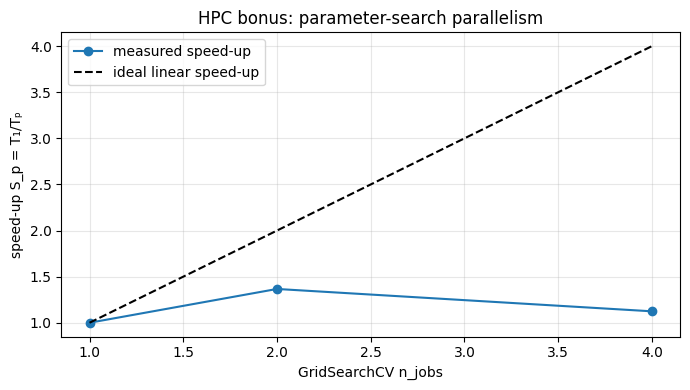

Discussion: speed-up is usually below ideal linear scaling because preprocessing, job scheduling, memory bandwidth and serial work cannot be parallelised perfectly (Amdahl's law). With only 12 fits, dispatch overhead may dominate


In [42]:
# Bonus A: empirical parallel speed-up study
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

# Limit this bonus experiment to about 12k chronologically ordered rows so the three
# measurements remain practical. The estimator is single-threaded so parallelism is
# provided by GridSearchCV across folds/parameter settings rather than nested forest jobs.
bonus_stride = max(1, int(np.ceil(len(Xs) / 12000)))
X_bonus = Xs.iloc[::bonus_stride].reset_index(drop=True)
y_bonus = ys.iloc[::bonus_stride].reset_index(drop=True)
bonus_base = RandomForestRegressor(n_estimators=40, min_samples_leaf=5, max_samples=0.5,
                                   bootstrap=True, n_jobs=1, random_state=SEED)
bonus_grid = {"model__max_depth": [12, None], "model__max_features": [0.7, 1.0]}
bonus_rows = []
for jobs in [1, 2, 4]:
    search_bonus = GridSearchCV(
        pipe(clone(bonus_base)), param_grid=bonus_grid, cv=TimeSeriesSplit(n_splits=3),
        scoring="neg_root_mean_squared_error", n_jobs=jobs, pre_dispatch=jobs,
        refit=False, return_train_score=False, error_score="raise"
    )
    started = time.perf_counter()
    search_bonus.fit(X_bonus, y_bonus)
    elapsed = time.perf_counter() - started
    bonus_rows.append({"n_jobs": jobs, "wall time (s)": elapsed,
                       "best CV RMSE": -float(search_bonus.best_score_),
                       "best parameters": search_bonus.best_params_})
bonus_results = pd.DataFrame(bonus_rows)
base_time = float(bonus_results.loc[bonus_results["n_jobs"] == 1, "wall time (s)"].iloc[0])
bonus_results["speed-up S_p"] = base_time / bonus_results["wall time (s)"]
bonus_results["efficiency E_p"] = bonus_results["speed-up S_p"] / bonus_results["n_jobs"]
display(bonus_results.round(3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(bonus_results["n_jobs"], bonus_results["speed-up S_p"], "o-", label="measured speed-up")
ax.plot(bonus_results["n_jobs"], bonus_results["n_jobs"], "k--", label="ideal linear speed-up")
ax.set_xlabel("GridSearchCV n_jobs"); ax.set_ylabel("speed-up S_p = T₁/Tₚ")
ax.set_title("HPC bonus: parameter-search parallelism"); ax.legend(); plt.tight_layout(); plt.show()
print("Discussion: speed-up is usually below ideal linear scaling because preprocessing, job scheduling, memory bandwidth and serial work cannot be parallelised perfectly (Amdahl's law). With only 12 fits, dispatch overhead may dominate")


<div style="background:linear-gradient(120deg,#0a2a5c,#1c5aa6);color:#e6eef8;padding:14px 22px;border-radius:10px;border-top:4px solid #d49a2a;margin-top:10px;">
<b style="color:#ffd98e;">Al-Khawarizmi Tour · Online Hackathon HPC &amp; AI</b> · Oct 3 – Nov 7, 2026 · 100% online<br>
<i>From the past to the future… Science without borders. Your ideas. A bigger tomorrow.</i> · © 2026 Dr. Rafik Borji</div>